<a href="https://colab.research.google.com/github/nmadhavan686-blip/gregarious-pasca-e9242b/blob/main/EDA%20ASS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

df = pd.read_csv(next(iter(files.upload())))
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df.head()

Saving social_media_viral_content_dataset.txt to social_media_viral_content_dataset.txt


,post_id,platform,content_type,topic,language,region,post_datetime,hashtags,views,likes,comments,shares,engagement_rate,sentiment_score,is_viral
0,SM_100000,Instagram,text,Sports,ur,UK,2024-12-10 00:00:00,#tech #funny #music,2319102,122058,15800,861,0.0598,0.464,1
1,SM_100001,Instagram,carousel,Sports,ur,Brazil,2024-10-13 00:00:00,#news #fyp #funny #ai #trending,2538464,110368,11289,54887,0.0695,-0.800,1
2,SM_100002,YouTube Shorts,video,Technology,ur,UK,2024-05-03 00:00:00,#ai #news,1051176,87598,47196,44132,0.1702,0.416,0
3,SM_100003,X,text,Politics,ur,US,2024-08-04 00:00:00,#ai #funny,5271440,329465,774,59736,0.0740,0.877,1
4,SM_100004,YouTube Shorts,text,Education,es,US,2024-03-28 00:00:00,#news #ai #viral #funny #fyp,3186256,199141,5316,83105,0.0903,0.223,1


In [4]:
df = df.drop_duplicates()
df = df.fillna(0)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_id          2000 non-null   object 
 1   platform         2000 non-null   object 
 2   content_type     2000 non-null   object 
 3   topic            2000 non-null   object 
 4   language         2000 non-null   object 
 5   region           2000 non-null   object 
 6   post_datetime    2000 non-null   object 
 7   hashtags         2000 non-null   object 
 8   views            2000 non-null   int64  
 9   likes            2000 non-null   int64  
 10  comments         2000 non-null   int64  
 11  shares           2000 non-null   int64  
 12  engagement_rate  2000 non-null   float64
 13  sentiment_score  2000 non-null   float64
 14  is_viral         2000 non-null   int64  
dtypes: float64(2), int64(5), object(8)
memory usage: 234.5+ KB


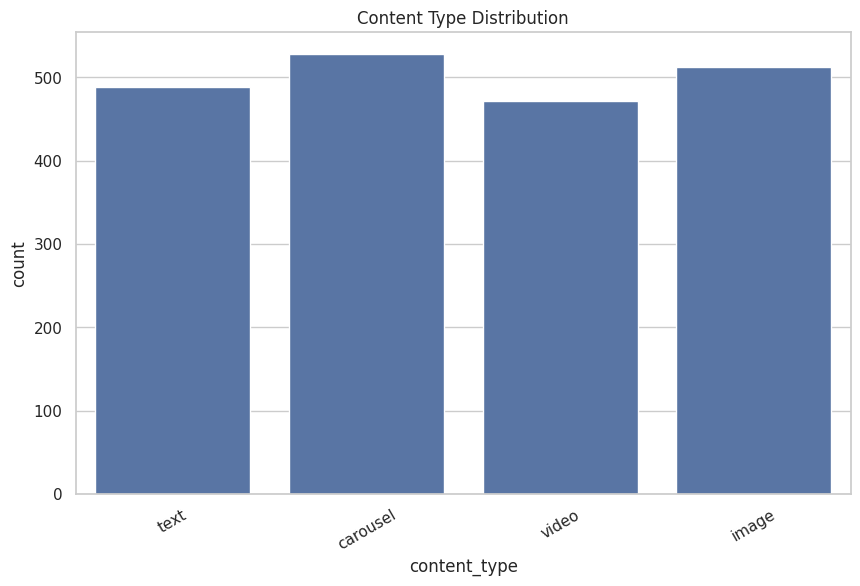

In [5]:
sns.countplot(data=df, x="content_type")
plt.title("Content Type Distribution")
plt.xticks(rotation=30)
plt.show()

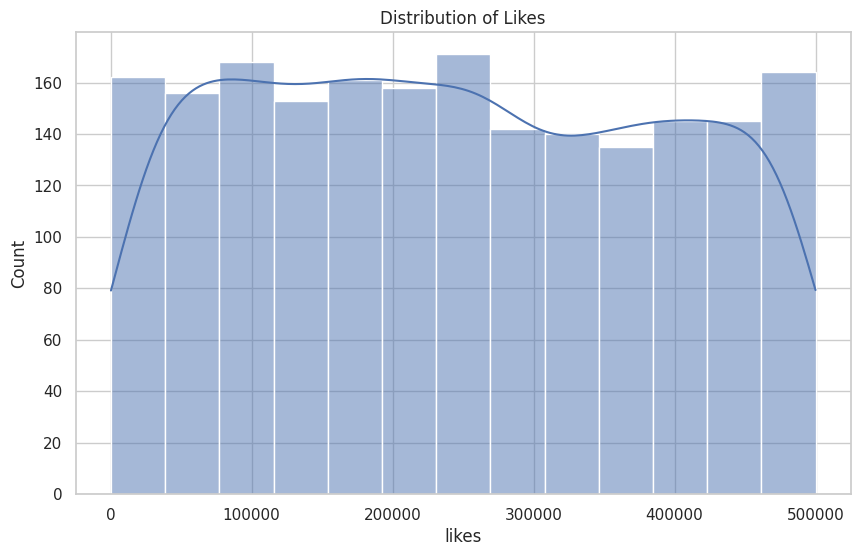

In [6]:
sns.histplot(df["likes"], kde=True)
plt.title("Distribution of Likes")
plt.show()

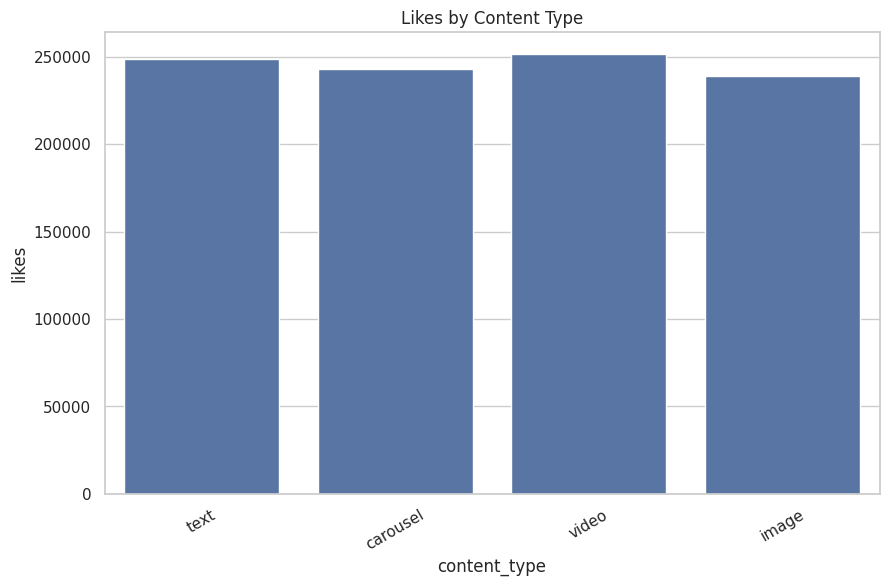

In [7]:
sns.barplot(data=df, x="content_type", y="likes", errorbar=None)
plt.title("Likes by Content Type")
plt.xticks(rotation=30)
plt.show()

Available columns: ['post_id', 'platform', 'content_type', 'topic', 'language', 'region', 'post_datetime', 'hashtags', 'views', 'likes', 'comments', 'shares', 'engagement_rate', 'sentiment_score', 'is_viral']


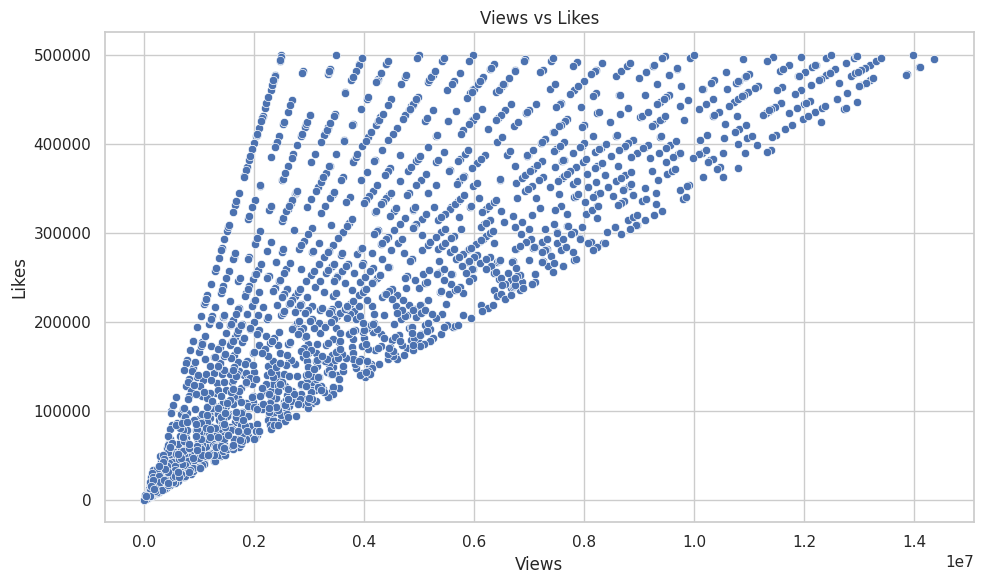

In [10]:
# Find the correct column names
print("Available columns:", df.columns.tolist())

# Use views if reach is not available
x_col = "reach" if "reach" in df.columns else "views"

if x_col in df.columns and "likes" in df.columns:
    sns.scatterplot(data=df, x=x_col, y="likes")
    plt.title(f"{x_col.title()} vs Likes")
    plt.xlabel(x_col.title())
    plt.ylabel("Likes")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found. Check the column names above.")

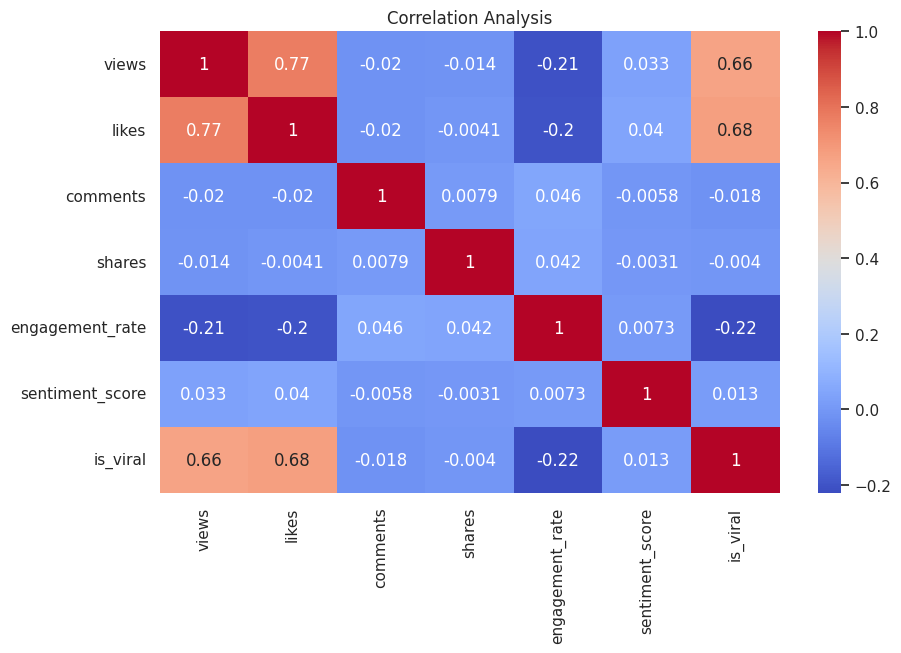

In [11]:
sns.heatmap(df.select_dtypes("number").corr(),
            annot=True, cmap="coolwarm")
plt.title("Correlation Analysis")
plt.show()

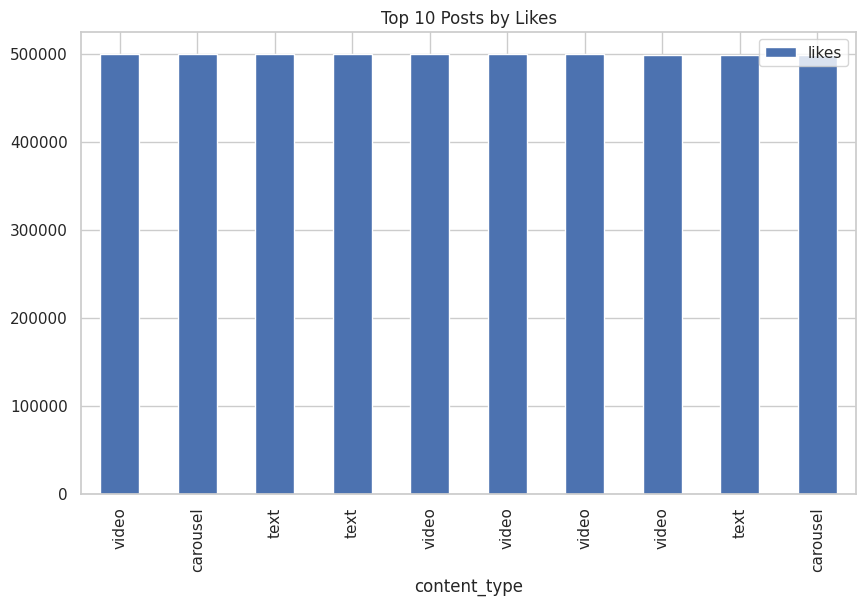

In [12]:
df.nlargest(10, "likes").plot(
    x="content_type", y="likes", kind="bar"
)
plt.title("Top 10 Posts by Likes")
plt.show()